# 01 · H₃: a learned matrix with and without a physics frame

Two coupled states of H₃ (FCI/cc-pVDZ). This notebook reproduces, through the `diabml` backend, the comparison of
**CDNN** (Shu, Varga, Zhang, Meng, Parameswaran, Zhou & Truhlar, *JCTC* **21**, 3342, 2025) with a **London-framed**
model, in which the network learns only corrections to the 2 × 2 valence-bond matrix built from exact H₂ curves.

| Model | What builds the matrix |
|---|---|
| `physics prior` | London matrix from H₂ singlet/triplet curves, no H₃ data |
| `CDNN` | 256-128-64 GELU network of (r₁₂, r₁₃, r₂₃), as in the paper |
| `CDNN + permutations` | CDNN trained on all six atom permutations of every geometry |
| `independent NN` | the same network predicting the two energies directly (no matrix) |
| `framed CDNN` | London matrix + learned Sato function and three-body corrections (exact symmetry and limits) |

Change the control cell and re-run. Defaults keep the run to roughly 10 minutes on a laptop.

In [1]:
# ---------------- controls ----------------
MODELS     = ['CDNN', 'CDNN + permutations', 'independent NN', 'framed CDNN']
EPOCHS     = 3000          # Adam steps per restart (the paper trained to convergence; 3000 is enough here)
RESTARTS   = 2             # random restarts per model, best kept on validation data (paper: 300)
N_TRAIN    = [25, 100]     # training-set sizes for the global-surface learning curve
SPLITS     = 1             # random splits per size
SEED       = 0

In [2]:
import sys, time, numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, '..')                      # the diabml package lives one level up
from diabml import RefSet
from diabml.units import EV_KCAL
from diabml import plotting as P, metrics as M
from diabml.models import CDNN, IndependentNN, FramedModel, KRR, train
P.style()
torch.set_num_threads(2)
DATA = '../data/'
from diabml.frames import LondonFrame
from diabml.geometry import H3_PERMUTATIONS
h2, cut, glob = RefSet.load(DATA + 'h2_curves.npz'), RefSet.load(DATA + 'h3_cut.npz'), RefSet.load(DATA + 'h3_global.npz')
frame = LondonFrame(h2)
print(cut, glob, sep='\n')

ModuleNotFoundError: No module named 'torch'

## Models

`make(name)` returns a fresh model and the keyword arguments its training needs. The permutation variant augments
training data; the framed model gets a larger learning rate because it starts from the physics and only needs small corrections.

In [3]:
def permute(coords, energies):
    return np.concatenate([coords[:, p] for p in H3_PERMUTATIONS]), np.concatenate([energies] * 6)

def make(name):
    if name == 'CDNN':                return CDNN(3, 2), {}
    if name == 'CDNN + permutations': return CDNN(3, 2), {'augment': permute}
    if name == 'independent NN':      return IndependentNN(3, 2), {}
    if name == 'framed CDNN':         return FramedModel(frame, 2), {'lr': 3e-3}
    raise ValueError(name)

def fit(name, data, tr, va):
    m, kw = make(name)
    kw = {'lr': 1e-3, **kw}
    return train(m, data.coords[tr], data.energies[tr], data.coords[va], data.energies[va], epochs=EPOCHS,
                 restarts=RESTARTS, **kw)

## Part A · The paper's cut through the conical intersection

r₂₃ = 1.08 Å; r₁₂, r₁₃ ∈ [0.88, 1.40] Å. The states are degenerate at r₁₂ = r₁₃ = 1.08 Å. Random 60/20/20 split.

In [4]:
tr, va, te = cut.split(265, 88, seed=SEED)
A, t0 = {}, time.time()
for name in MODELS:
    A[name] = fit(name, cut, tr, va)
    print(f'{name} trained ({time.time() - t0:.0f} s)')
predictors = {'physics prior': frame.prior_energies, **{k: m.predict for k, m in A.items()}}
rows = {}
for k, f in predictors.items():
    mue = M.mue_mev(f(cut.coords[te]), cut.energies[te])
    # on the 2D cut only the r12 <-> r13 swap stays inside the slice the models were trained on
    rows[k] = [mue[0], mue[1], M.gap_mev(f, [[1.08, 1.08, 1.08]]), M.permutation_error_mev(f, cut.coords, [[0, 1, 2], [1, 0, 2]])]
print(M.summary_table(rows, ['MUE S0 meV', 'MUE S1 meV', 'gap@CI meV', 'swap meV']))

CDNN trained (22 s)


CDNN + permutations trained (92 s)


independent NN trained (111 s)


framed CDNN trained (134 s)
                       MUE S0 meV  MUE S1 meV  gap@CI meV    swap meV
physics prior              304.89      486.63        0.00        0.00
CDNN                         3.79        3.29        3.39        2.54
CDNN + permutations          3.12        2.98        4.27        1.73
independent NN               8.50        6.50      330.06        3.41
framed CDNN                  7.71        9.22        0.00        0.00


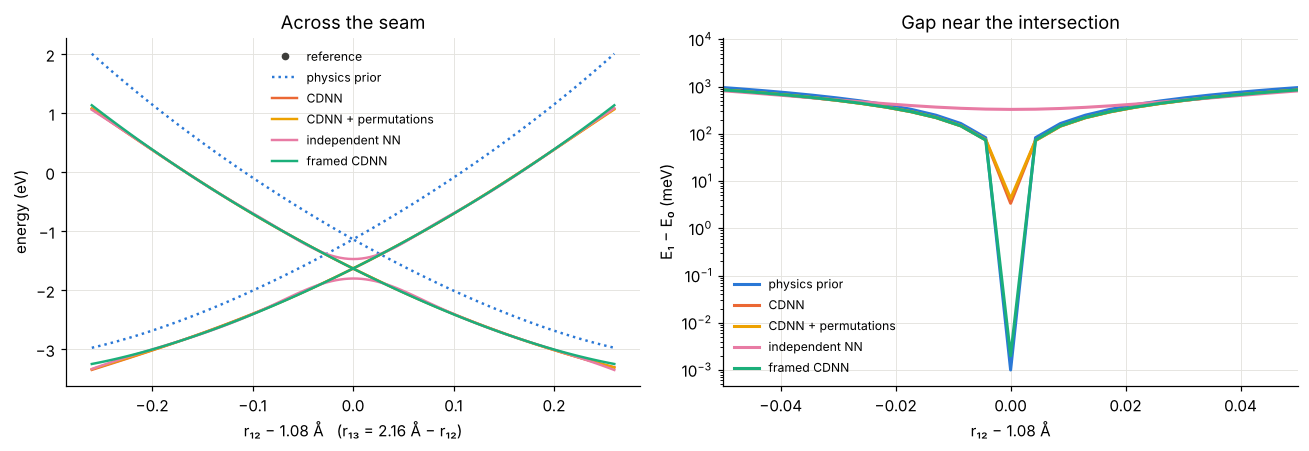

In [5]:
d = np.linspace(-0.26, 0.26, 121)
C = np.c_[1.08 + d, 1.08 - d, np.full_like(d, 1.08)]
near = np.abs(cut.coords[:, 0] + cut.coords[:, 1] - 2.16) < 1e-6
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
P.cut_plot(d, cut.energies[near], {k: f(C) for k, f in predictors.items()}, 'r₁₂ − 1.08 Å   (r₁₃ = 2.16 Å − r₁₂)',
           title='Across the seam', ax=axes[0], ref_x=cut.coords[near, 0] - 1.08)
for k, f in predictors.items():
    E = f(C)
    axes[1].semilogy(d, np.maximum((E[:, 1] - E[:, 0]) * 1000, 1e-3), color=P.color(k), label=k)
axes[1].set(xlim=(-0.05, 0.05), xlabel='r₁₂ − 1.08 Å', ylabel='E₁ − E₀ (meV)', title='Gap near the intersection')
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### What the matrices look like

A conical intersection needs Ω₁₁ = Ω₂₂ **and** Ω₁₂ = 0 at once: the two zero lines must cross at the star. The framed
matrix does this by symmetry; CDNN has to learn it.

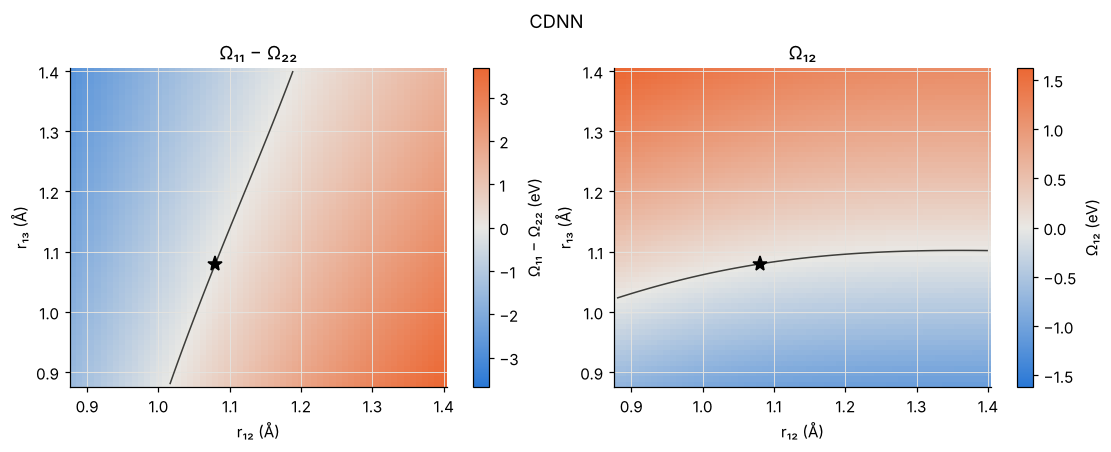

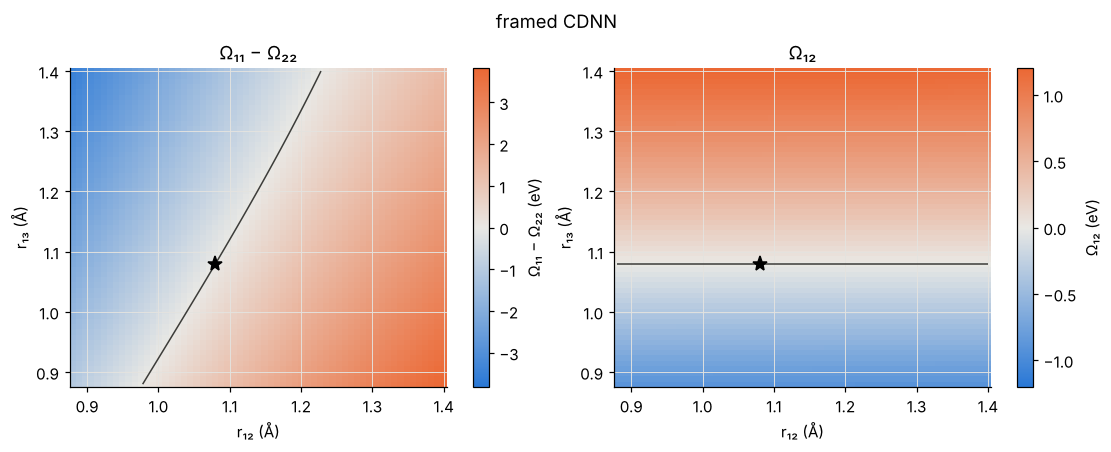

In [6]:
g = np.linspace(0.88, 1.40, 61); G1, G2 = np.meshgrid(g, g, indexing='ij')
Rg = np.c_[G1.ravel(), G2.ravel(), np.full(G1.size, 1.08)]
for k in [m for m in ('CDNN', 'framed CDNN') if m in A]:
    Mx = A[k].matrix(Rg).detach().numpy().reshape(*G1.shape, 2, 2)
    fig = P.matrix_maps(G1, G2, Mx, 'r₁₂ (Å)', 'r₁₃ (Å)', marker=(1.08, 1.08)); fig.suptitle(k); plt.show()

## Part B · The global surface and its symmetry

Same geometry window as the earlier exploratory notebooks (all H–H ≥ 0.6 Å, ground state within 5.4 eV of 3 H).
Reported: test RMSE per state, the mean gap at nine equilateral geometries (exactly 0 in FCI), and the change on
relabelling identical atoms (exactly 0 physically).

In [7]:
W = np.where((glob.coords.min(1) >= 0.6) & (glob.energies[:, 0] <= 5.44))[0]
bend = glob.extra['bend_geometry']
seam = glob.coords[(bend[:, 2] == 60) & (bend[:, 0] == bend[:, 1])]
B = {k: {n: [] for n in N_TRAIN} for k in MODELS}
t0 = time.time()
for s in range(SPLITS):
    p = np.random.default_rng(10 + s).permutation(W); va, pool = p[:60], p[60:]
    for n in N_TRAIN:
        tr, te = pool[:n], pool[n:]
        for k in MODELS:
            m = fit(k, glob, tr, va)
            B[k][n].append(list(M.rmse_kcal(m.predict(glob.coords[te]), glob.energies[te]))
                           + [M.gap_mev(m, seam), M.permutation_error_mev(m, glob.coords[te], H3_PERMUTATIONS)])
        print(f'split {s}, n = {n} done ({time.time() - t0:.0f} s)')
prior = M.rmse_kcal(frame.prior_energies(glob.coords[te]), glob.energies[te])
rows = {f'{k}, n={n}': list(np.mean(B[k][n], 0)) for k in MODELS for n in N_TRAIN}
rows['physics prior (0 H3 points)'] = list(prior) + [M.gap_mev(frame.prior_energies, seam), 0.0]
print(M.summary_table(rows, ['S0 kcal', 'S1 kcal', 'seam meV', 'swap meV']))

split 0, n = 25 done (57 s)


split 0, n = 100 done (139 s)
                                  S0 kcal     S1 kcal    seam meV    swap meV
CDNN, n=25                          16.71       21.81     1546.29      977.90
CDNN, n=100                          3.83        4.55      362.23      542.24
CDNN + permutations, n=25           12.96       31.20     1336.41      196.74
CDNN + permutations, n=100           1.85        2.20       54.90       30.52
independent NN, n=25                19.80       28.52     1700.20     1396.77
independent NN, n=100                3.53        5.48      487.67     1099.51
framed CDNN, n=25                    1.19        5.75        0.00        0.00
framed CDNN, n=100                   0.98        5.50        0.00        0.00
physics prior (0 H3 points)          6.03       13.47        0.00        0.00


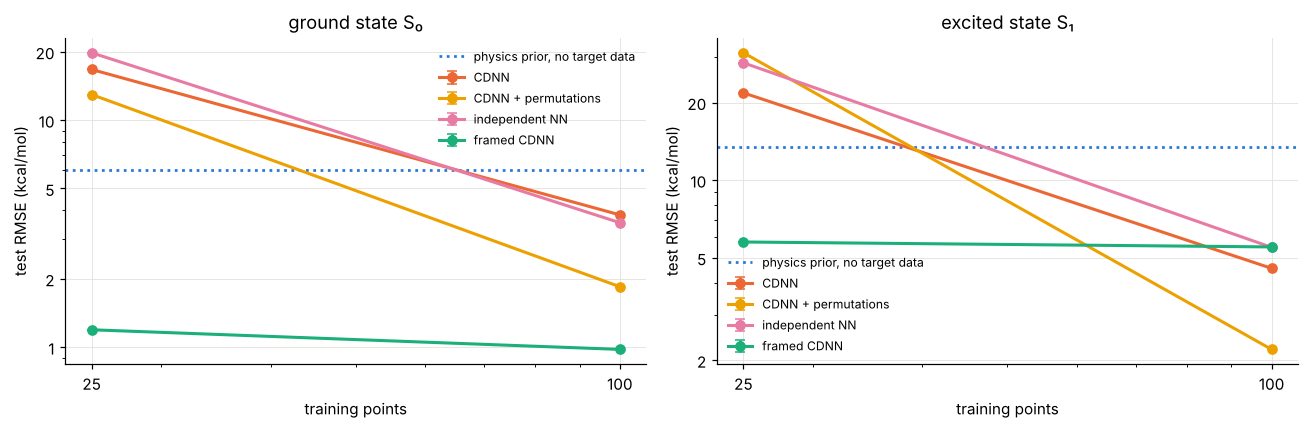

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, ax in enumerate(axes):
    P.learning_curves(N_TRAIN, {k: [[x[s] for x in B[k][n]] for n in N_TRAIN] for k in MODELS}, baseline=prior[s],
                      title=['ground state S₀', 'excited state S₁'][s], ax=ax)
plt.tight_layout(); plt.show()

## Explore

Move the third distance and watch every model along a cut through r₁₂ = r₁₃ (needs `ipywidgets`; otherwise a static plot).

In [9]:
from diabml.ui import cut_explorer
cut_explorer(lambda x, r23: np.c_[x, x, np.full_like(x, r23)],
             {'physics prior': frame.prior_energies, **{k: m for k, m in A.items() if k != 'independent NN'}},
             x_range=(0.8, 2.5), fixed={'r23': (1.08, 0.8, 2.5)}, xlabel='r₁₂ = r₁₃ (Å)')

interactive(children=(FloatSlider(value=1.08, description='r23', max=2.5, min=0.8, step=0.034), Output()), _do…

<function diabml.ui.cut_explorer.<locals>.draw(**kw)>